In [1]:
import pandas
import numpy
import matplotlib
import seaborn
import sklearn
import joblib

Matplotlib is building the font cache; this may take a moment.


In [2]:
import pandas as pd
import numpy as np

np.random.seed(42)

number_of_students = 500

data = {
    "age": np.random.randint(18, 23, number_of_students),
    "attendance": np.random.randint(50, 101, number_of_students),
    "study_hours": np.round(np.random.uniform(1, 8, number_of_students), 1),
    "previous_score": np.random.randint(40, 101, number_of_students),
    "assignment_marks": np.random.randint(40, 101, number_of_students),
    "internal_marks": np.random.randint(40, 101, number_of_students),
    "participation": np.random.randint(40, 101, number_of_students),
    "sleep_hours": np.round(np.random.uniform(5, 9, number_of_students), 1),
    "extracurricular": np.random.choice(
        ["Yes", "No"],
        number_of_students
    )
}

df = pd.DataFrame(data)

print(df.head())

   age  attendance  study_hours  previous_score  assignment_marks  \
0   21          69          1.9              61                40   
1   22          97          6.1              50                63   
2   20          74          7.6              66                93   
3   22          71          2.3              42                46   
4   22          62          1.5              56                64   

   internal_marks  participation  sleep_hours extracurricular  
0              66             67          8.2              No  
1              67             53          7.6             Yes  
2              61             95          7.7              No  
3              53             49          5.5             Yes  
4              46             55          5.9              No  


In [3]:
# Final score calculate karna

df["final_score"] = (
    0.20 * df["attendance"] +
    0.20 * df["study_hours"] * 10 +
    0.25 * df["previous_score"] +
    0.15 * df["assignment_marks"] +
    0.15 * df["internal_marks"] +
    0.05 * df["participation"]
)

# Score ko 0-100 ke range mein rakhna
df["final_score"] = df["final_score"].clip(0, 100)

# Final score ko 2 decimal places tak rakhna
df["final_score"] = df["final_score"].round(2)

print(df.head())

   age  attendance  study_hours  previous_score  assignment_marks  \
0   21          69          1.9              61                40   
1   22          97          6.1              50                63   
2   20          74          7.6              66                93   
3   22          71          2.3              42                46   
4   22          62          1.5              56                64   

   internal_marks  participation  sleep_hours extracurricular  final_score  
0              66             67          8.2              No        52.10  
1              67             53          7.6             Yes        66.25  
2              61             95          7.7              No        74.35  
3              53             49          5.5             Yes        46.60  
4              46             55          5.9              No        48.65  


In [4]:
df.to_csv("../data/student_performance.csv", index=False)

print("Dataset successfully saved!")

Dataset successfully saved!


In [5]:
df.head()

,age,attendance,study_hours,previous_score,assignment_marks,internal_marks,participation,sleep_hours,extracurricular,final_score
0,21,69,1.9,61,40,66,67,8.2,No,52.10
1,22,97,6.1,50,63,67,53,7.6,Yes,66.25
2,20,74,7.6,66,93,61,95,7.7,No,74.35
3,22,71,2.3,42,46,53,49,5.5,Yes,46.60
4,22,62,1.5,56,64,46,55,5.9,No,48.65


In [6]:
df.shape

(500, 10)

In [7]:
df.columns

Index(['age', 'attendance', 'study_hours', 'previous_score',
       'assignment_marks', 'internal_marks', 'participation', 'sleep_hours',
       'extracurricular', 'final_score'],
      dtype='str')

In [8]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 10 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   age               500 non-null    int32  
 1   attendance        500 non-null    int32  
 2   study_hours       500 non-null    float64
 3   previous_score    500 non-null    int32  
 4   assignment_marks  500 non-null    int32  
 5   internal_marks    500 non-null    int32  
 6   participation     500 non-null    int32  
 7   sleep_hours       500 non-null    float64
 8   extracurricular   500 non-null    str    
 9   final_score       500 non-null    float64
dtypes: float64(3), int32(6), str(1)
memory usage: 28.7 KB


In [9]:
df.describe()

,age,attendance,study_hours,previous_score,assignment_marks,internal_marks,participation,sleep_hours,final_score
count,500.000000,500.000000,500.00000,500.000000,500.000000,500.000000,500.000000,500.00000,500.000000
mean,19.970000,74.508000,4.54020,70.022000,68.344000,70.702000,70.274000,7.05200,65.858100
std,1.425891,15.015888,2.05677,17.742692,17.606181,17.356604,17.731207,1.15242,7.599635
min,18.000000,50.000000,1.00000,40.000000,40.000000,40.000000,40.000000,5.00000,46.600000
25%,19.000000,61.000000,2.60000,54.000000,53.000000,57.000000,55.000000,6.10000,61.137500
50%,20.000000,74.000000,4.70000,70.000000,68.000000,70.000000,69.500000,7.10000,66.200000
75%,21.000000,87.000000,6.30000,85.250000,83.000000,86.000000,86.000000,8.00000,71.012500
max,22.000000,100.000000,8.00000,100.000000,100.000000,100.000000,100.000000,9.00000,86.250000


In [10]:
df.isnull().sum()

age                 0
attendance          0
study_hours         0
previous_score      0
assignment_marks    0
internal_marks      0
participation       0
sleep_hours         0
extracurricular     0
final_score         0
dtype: int64

In [11]:
df.duplicated().sum()

np.int64(0)

In [12]:
print("Minimum attendance:", df["attendance"].min())
print("Maximum attendance:", df["attendance"].max())

Minimum attendance: 50
Maximum attendance: 100


In [13]:
print("Minimum study hours:", df["study_hours"].min())
print("Maximum study hours:", df["study_hours"].max())

Minimum study hours: 1.0
Maximum study hours: 8.0


In [14]:
print("Minimum final score:", df["final_score"].min())
print("Maximum final score:", df["final_score"].max())

Minimum final score: 46.6
Maximum final score: 86.25


In [15]:
df["extracurricular"].value_counts()

extracurricular
Yes    262
No     238
Name: count, dtype: int64

In [16]:
df["extracurricular"] = df["extracurricular"].map({
    "Yes": 1,
    "No": 0
})

In [17]:
df.head()

,age,attendance,study_hours,previous_score,assignment_marks,internal_marks,participation,sleep_hours,extracurricular,final_score
0,21,69,1.9,61,40,66,67,8.2,0,52.10
1,22,97,6.1,50,63,67,53,7.6,1,66.25
2,20,74,7.6,66,93,61,95,7.7,0,74.35
3,22,71,2.3,42,46,53,49,5.5,1,46.60
4,22,62,1.5,56,64,46,55,5.9,0,48.65


In [18]:
print("Missing values:")
print(df.isnull().sum())

print("\nDuplicate rows:")
print(df.duplicated().sum())

print("\nDataset shape:")
print(df.shape)

Missing values:
age                 0
attendance          0
study_hours         0
previous_score      0
assignment_marks    0
internal_marks      0
participation       0
sleep_hours         0
extracurricular     0
final_score         0
dtype: int64

Duplicate rows:
0

Dataset shape:
(500, 10)


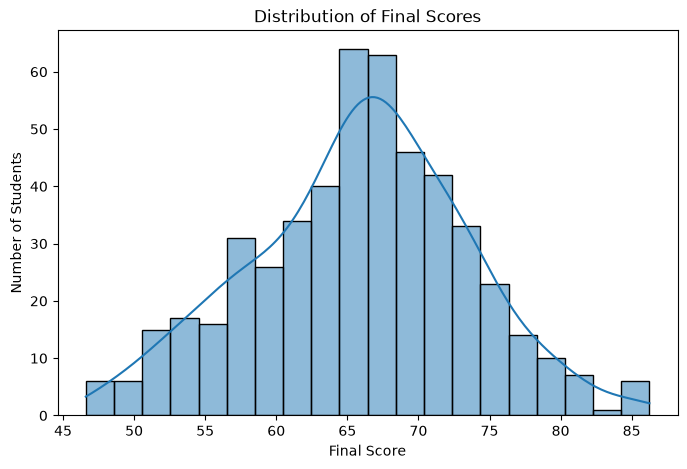

In [19]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 5))

sns.histplot(
    df["final_score"],
    bins=20,
    kde=True
)

plt.title("Distribution of Final Scores")
plt.xlabel("Final Score")
plt.ylabel("Number of Students")

plt.show()

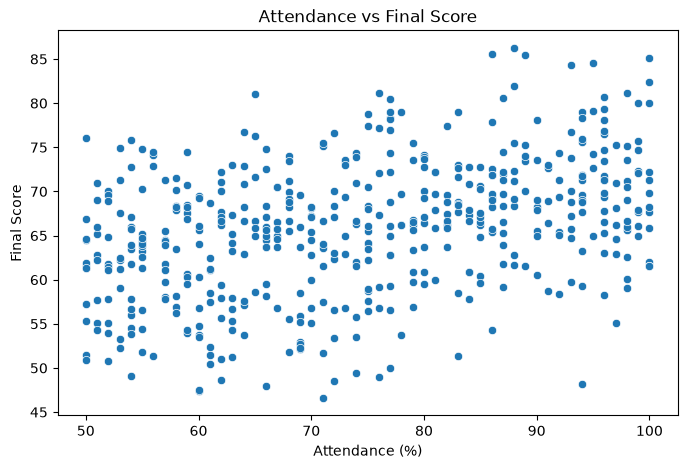

In [20]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x="attendance",
    y="final_score"
)

plt.title("Attendance vs Final Score")
plt.xlabel("Attendance (%)")
plt.ylabel("Final Score")

plt.show()

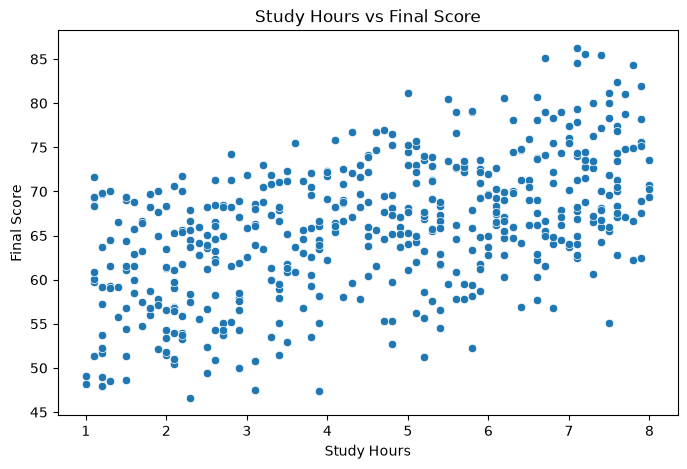

In [21]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x="study_hours",
    y="final_score"
)

plt.title("Study Hours vs Final Score")
plt.xlabel("Study Hours")
plt.ylabel("Final Score")

plt.show()

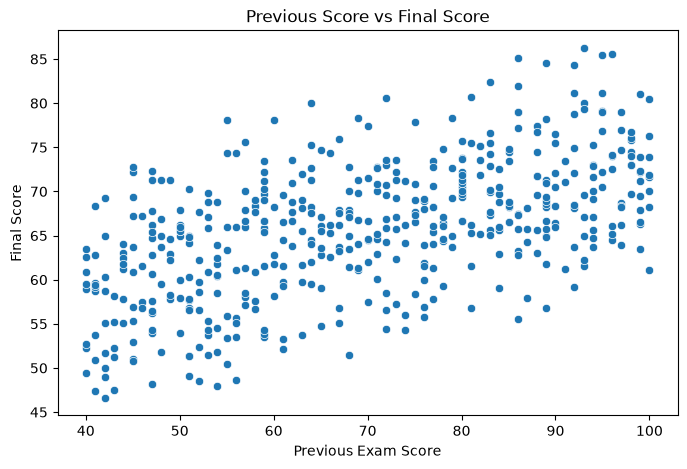

In [22]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x="previous_score",
    y="final_score"
)

plt.title("Previous Score vs Final Score")
plt.xlabel("Previous Exam Score")
plt.ylabel("Final Score")

plt.show()

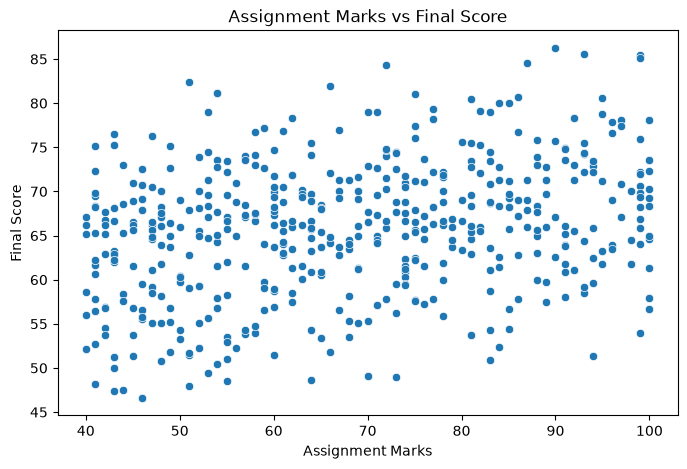

In [23]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x="assignment_marks",
    y="final_score"
)

plt.title("Assignment Marks vs Final Score")
plt.xlabel("Assignment Marks")
plt.ylabel("Final Score")

plt.show()

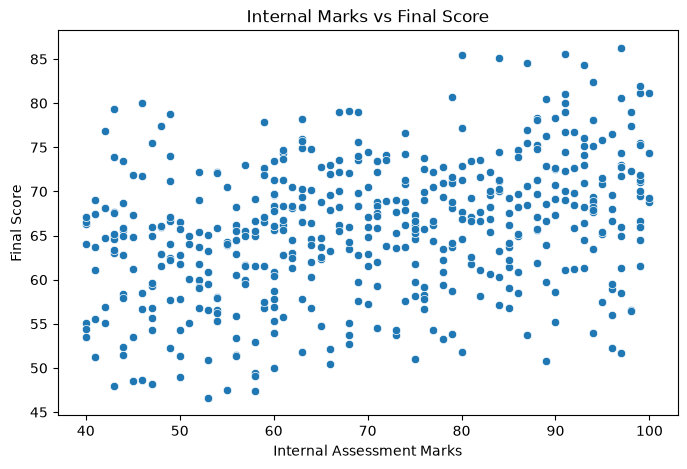

In [24]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x="internal_marks",
    y="final_score"
)

plt.title("Internal Marks vs Final Score")
plt.xlabel("Internal Assessment Marks")
plt.ylabel("Final Score")

plt.show()

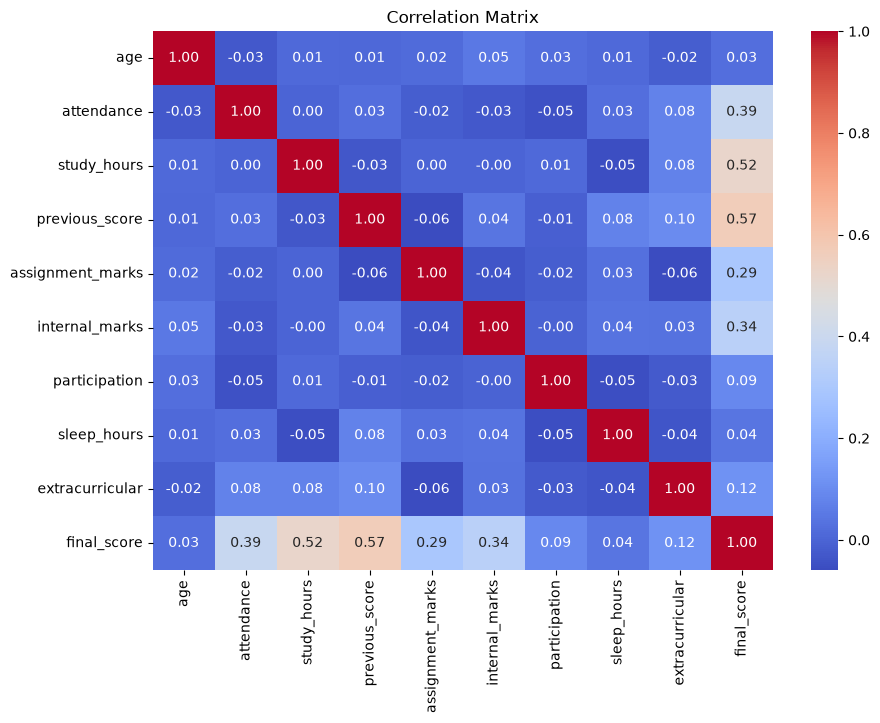

In [25]:
correlation = df.corr(numeric_only=True)

plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Matrix")

plt.show()

In [26]:
X = df.drop("final_score", axis=1)

print(X.head())

   age  attendance  study_hours  previous_score  assignment_marks  \
0   21          69          1.9              61                40   
1   22          97          6.1              50                63   
2   20          74          7.6              66                93   
3   22          71          2.3              42                46   
4   22          62          1.5              56                64   

   internal_marks  participation  sleep_hours  extracurricular  
0              66             67          8.2                0  
1              67             53          7.6                1  
2              61             95          7.7                0  
3              53             49          5.5                1  
4              46             55          5.9                0  


In [27]:
y = df["final_score"]

print(y.head())

0    52.10
1    66.25
2    74.35
3    46.60
4    48.65
Name: final_score, dtype: float64


In [28]:
print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (500, 9)
Target shape: (500,)


In [29]:
print(X.columns)

Index(['age', 'attendance', 'study_hours', 'previous_score',
       'assignment_marks', 'internal_marks', 'participation', 'sleep_hours',
       'extracurricular'],
      dtype='str')


In [30]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

In [31]:
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (400, 9)
X_test: (100, 9)
y_train: (400,)
y_test: (100,)


In [32]:
print("Total data:", len(df))
print("Training data:", len(X_train))
print("Testing data:", len(X_test))

Total data: 500
Training data: 400
Testing data: 100


In [33]:
from sklearn.linear_model import LinearRegression

In [34]:
linear_model = LinearRegression()

In [35]:
linear_model.fit(X_train, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](9,)","[-0. , 0.2 , 2. ,..., 0.05,-0. ,-0. ]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](9,)","['age','attendance','study_hours',...,'participation','sleep_hours', 'extracurricular']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,1.421e-14
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,9
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(9)


In [36]:
linear_predictions = linear_model.predict(X_test)

In [37]:
print(linear_predictions[:10])

[76.9  64.3  69.15 55.1  59.95 71.25 70.1  61.8  72.85 49.1 ]


In [38]:
comparison = pd.DataFrame({
    "Actual Score": y_test.values,
    "Predicted Score": linear_predictions
})

print(comparison.head(10))

   Actual Score  Predicted Score
0         76.90            76.90
1         64.30            64.30
2         69.15            69.15
3         55.10            55.10
4         59.95            59.95
5         71.25            71.25
6         70.10            70.10
7         61.80            61.80
8         72.85            72.85
9         49.10            49.10


In [39]:
from sklearn.metrics import mean_absolute_error

mae = mean_absolute_error(
    y_test,
    linear_predictions
)

print("MAE:", mae)

MAE: 1.7195134205394424e-14


In [40]:
from sklearn.metrics import mean_squared_error

mse = mean_squared_error(
    y_test,
    linear_predictions
)

rmse = np.sqrt(mse)

print("RMSE:", rmse)

RMSE: 2.1481435592578145e-14


In [41]:
from sklearn.metrics import r2_score

r2 = r2_score(
    y_test,
    linear_predictions
)

print("R² Score:", r2)

R² Score: 1.0


In [42]:
print("Linear Regression Results")
print("-------------------------")
print("MAE :", mae)
print("RMSE:", rmse)
print("R²  :", r2)

Linear Regression Results
-------------------------
MAE : 1.7195134205394424e-14
RMSE: 2.1481435592578145e-14
R²  : 1.0


In [43]:
from sklearn.tree import DecisionTreeRegressor

In [44]:
tree_model = DecisionTreeRegressor(
    random_state=42
)

In [45]:
tree_model.fit(X_train, y_train)

,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 0.24 Poisson deviance criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.For an example of how ``max_depth`` influences the model, see:ref:`sphx_glr_auto_examples_tree_plot_tree_regression.py`.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with

In [46]:
tree_predictions = tree_model.predict(X_test)

In [47]:
print(tree_predictions[:10])

[72.6  65.95 75.45 65.55 52.4  68.6  63.2  65.2  76.6  51.35]


In [48]:
tree_comparison = pd.DataFrame({
    "Actual Score": y_test.values,
    "Predicted Score": tree_predictions
})

print(tree_comparison.head(10))

   Actual Score  Predicted Score
0         76.90            72.60
1         64.30            65.95
2         69.15            75.45
3         55.10            65.55
4         59.95            52.40
5         71.25            68.60
6         70.10            63.20
7         61.80            65.20
8         72.85            76.60
9         49.10            51.35


In [49]:
tree_mae = mean_absolute_error(
    y_test,
    tree_predictions
)

print("Decision Tree MAE:", tree_mae)

Decision Tree MAE: 3.8585000000000007


In [50]:
tree_mse = mean_squared_error(
    y_test,
    tree_predictions
)

tree_rmse = np.sqrt(tree_mse)

print("Decision Tree RMSE:", tree_rmse)

Decision Tree RMSE: 4.638854923362015


In [51]:
tree_r2 = r2_score(
    y_test,
    tree_predictions
)

print("Decision Tree R²:", tree_r2)

Decision Tree R²: 0.6619277729818871


In [52]:
print("Decision Tree Results")
print("--------------------")
print("MAE :", tree_mae)
print("RMSE:", tree_rmse)
print("R²  :", tree_r2)

Decision Tree Results
--------------------
MAE : 3.8585000000000007
RMSE: 4.638854923362015
R²  : 0.6619277729818871


In [53]:
from sklearn.preprocessing import StandardScaler

In [54]:
scaler = StandardScaler()

In [55]:
X_train_scaled = scaler.fit_transform(X_train)

In [56]:
X_test_scaled = scaler.transform(X_test)

In [57]:
print(X_train_scaled[:5])

[[-0.00355786  0.56679515 -0.71272247  1.08803034 -1.38079397  1.06646924
   0.10226251  0.73224874 -1.05131497]
 [-0.00355786  0.16409877  1.14294411  0.91769291  0.17730601  1.18434371
   0.55425153 -0.98161607  0.95118973]
 [ 0.70801471 -0.64129398  1.04527745 -1.58058941  0.17730601  1.53796711
  -0.74521689 -0.12468366 -1.05131497]
 [-0.71513043 -0.77552611  0.11744416  0.29312233 -0.63059769  1.12540647
   0.89324329 -0.12468366 -1.05131497]
 [-1.426703    1.17083972  1.24061078 -0.84246054  0.29272082  1.71477881
  -1.59269629  1.24640818  0.95118973]]


In [58]:
from sklearn.neighbors import KNeighborsRegressor

In [59]:
knn_model = KNeighborsRegressor(
    n_neighbors=5
)

In [60]:
knn_model.fit(
    X_train_scaled,
    y_train
)

,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",5
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Uniform weights are used by default.See the following example for a demonstration of the impact ofdifferent weighting schemes on predictions::ref:`sphx_glr_auto_examples_neighbors_plot_regression.py`.",'uniform'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this isequivalent to using manhattan_distance (l1), and euclidean_distance(l2) for p = 2. For arbitrary p, minkowski_distance (l_p) is used.",2
,"metric metric: str, DistanceMetric object or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance<https://docs.scipy.org/doc/scipy/reference/spatial.distance.html>`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.If metric is a DistanceMetric object, it will be passed directly tothe underlying computation routines.",'minkowski'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.Doesn't affect :meth:`fit` method.",None
Name,Type,Value
"effective_metric_ effective_metric_: str or callableThe distance metric to use. It will be same as the `metric` parameteror a synonym of it, e.g. 'euclidean' if the `metric` parameter set to'minkowski' and `p` parameter set to 2.",str,'eu...an'
"effective_metric_params_ effective_metric_params_: dictAdditional keyword arguments for the metric function. For most metricswill be same with `metric_params` parameter, but may also contain the`p` parameter value if the `effective_metric_` attribute is set to'minkowski'.",dict,{}


In [61]:
knn_predictions = knn_model.predict(
    X_test_scaled
)

In [62]:
print(knn_predictions[:10])

[70.52 70.73 64.74 58.3  59.73 69.13 69.57 63.4  74.84 53.14]


In [63]:
knn_mae = mean_absolute_error(
    y_test,
    knn_predictions
)

print("KNN MAE:", knn_mae)

KNN MAE: 2.6592000000000007


In [64]:
knn_mse = mean_squared_error(
    y_test,
    knn_predictions
)

knn_rmse = np.sqrt(knn_mse)

print("KNN RMSE:", knn_rmse)

KNN RMSE: 3.3193496350942016


In [65]:
knn_r2 = r2_score(
    y_test,
    knn_predictions
)

print("KNN R²:", knn_r2)

KNN R²: 0.8269012571831054


In [66]:
print("KNN Results")
print("-----------")
print("MAE :", knn_mae)
print("RMSE:", knn_rmse)
print("R²  :", knn_r2)

KNN Results
-----------
MAE : 2.6592000000000007
RMSE: 3.3193496350942016
R²  : 0.8269012571831054


In [67]:
from sklearn.ensemble import RandomForestRegressor

In [68]:
forest_model = RandomForestRegressor(
    n_estimators=100,
    random_state=42
)

In [69]:
forest_model.fit(X_train, y_train)

,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",1.0
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease o

In [70]:
forest_predictions = forest_model.predict(X_test)

In [71]:
print(forest_predictions[:10])

[75.397  66.9015 69.138  56.1475 58.216  68.4365 67.607  61.661  72.7505
 52.803 ]


In [72]:
forest_mae = mean_absolute_error(
    y_test,
    forest_predictions
)

print("Random Forest MAE:", forest_mae)

Random Forest MAE: 2.1882549999999963


In [73]:
forest_mse = mean_squared_error(
    y_test,
    forest_predictions
)

forest_rmse = np.sqrt(forest_mse)

print("Random Forest RMSE:", forest_rmse)

Random Forest RMSE: 2.6697642157126853


In [75]:
forest_r2 = r2_score(
    y_test,
    forest_predictions
)

print("Random Forest R²:", forest_r2)

Random Forest R²: 0.8880217363852948


In [76]:
print("Random Forest Results")
print("--------------------")
print("MAE :", forest_mae)
print("RMSE:", forest_rmse)
print("R²  :", forest_r2)

Random Forest Results
--------------------
MAE : 2.1882549999999963
RMSE: 2.6697642157126853
R²  : 0.8880217363852948


In [77]:
results = pd.DataFrame({
    "Model": [
        "Linear Regression",
        "Decision Tree",
        "KNN",
        "Random Forest"
    ],
    "MAE": [
        mae,
        tree_mae,
        knn_mae,
        forest_mae
    ],
    "RMSE": [
        rmse,
        tree_rmse,
        knn_rmse,
        forest_rmse
    ],
    "R2 Score": [
        r2,
        tree_r2,
        knn_r2,
        forest_r2
    ]
})

print(results)

               Model           MAE          RMSE  R2 Score
0  Linear Regression  1.719513e-14  2.148144e-14  1.000000
1      Decision Tree  3.858500e+00  4.638855e+00  0.661928
2                KNN  2.659200e+00  3.319350e+00  0.826901
3      Random Forest  2.188255e+00  2.669764e+00  0.888022


In [78]:
best_model_row = results.loc[
    results["R2 Score"].idxmax()
]

print("Best Model:")
print(best_model_row)

Best Model:
Model       Linear Regression
MAE                       0.0
RMSE                      0.0
R2 Score                  1.0
Name: 0, dtype: object


In [79]:
final_model = forest_model

In [80]:
import joblib

joblib.dump(final_model, "../model/scorevision_model.pkl")

print("ScoreVision model saved successfully!")

ScoreVision model saved successfully!


In [81]:
student = pd.DataFrame({
    "age": [20],
    "attendance": [85],
    "study_hours": [4.5],
    "previous_score": [78],
    "assignment_marks": [82],
    "internal_marks": [80],
    "participation": [75],
    "sleep_hours": [7],
    "extracurricular": [1]
})

predicted_score = final_model.predict(student)

print("Predicted Final Score:", predicted_score[0])

Predicted Final Score: 71.738


In [82]:
score = predicted_score[0]

if score >= 85:
    category = "Excellent"
elif score >= 70:
    category = "Good"
elif score >= 50:
    category = "Average"
else:
    category = "Needs Improvement"

print("Predicted Score:", round(score, 2))
print("Performance Category:", category)

Predicted Score: 71.74
Performance Category: Good


In [83]:
feature_importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": final_model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

print(feature_importance)

            Feature  Importance
3    previous_score    0.340019
2       study_hours    0.309662
1        attendance    0.117171
5    internal_marks    0.099695
4  assignment_marks    0.092283
6     participation    0.017825
7       sleep_hours    0.013627
0               age    0.007237
8   extracurricular    0.002480


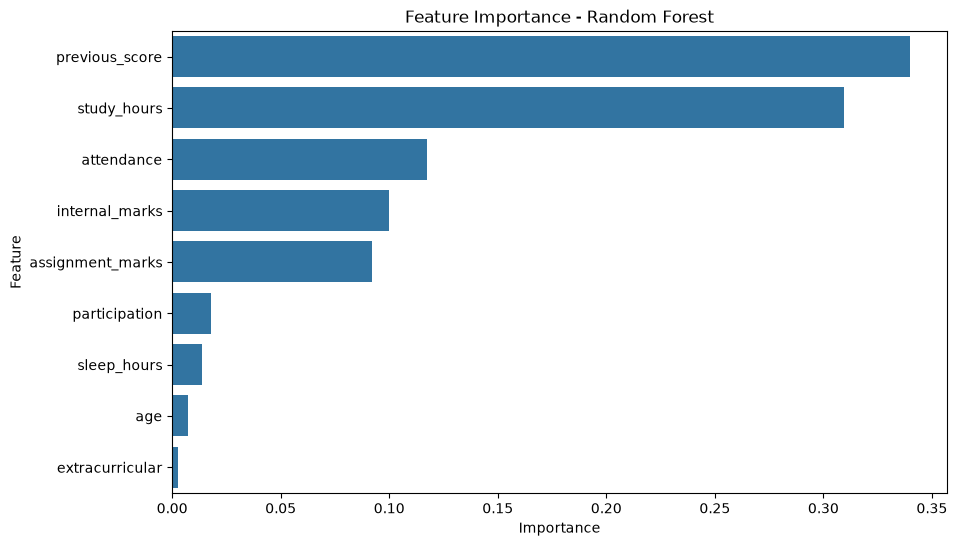

In [84]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=feature_importance,
    x="Importance",
    y="Feature"
)

plt.title("Feature Importance - Random Forest")
plt.xlabel("Importance")
plt.ylabel("Feature")

plt.show()

In [85]:
top_features = feature_importance.head(3)

print("Top 3 Important Factors:")
print(top_features)

Top 3 Important Factors:
          Feature  Importance
3  previous_score    0.340019
2     study_hours    0.309662
1      attendance    0.117171
